# Quiz 7

k-means with 3 clusters on a 2D dataset (quiz7-data.csv, columns X1, X2), started from two different sets of initial centres: cluster centres, labels, inertia, a between-cluster separation measure, the plot, and the overall and per-cluster silhouette.

In [1]:
from os import sep
from numpy.core.fromnumeric import mean
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn.cluster import KMeans

csv_data = pd.read_csv("./quiz7-data.csv")
data = csv_data.loc[:, ["X1", "X2"]]

In [2]:
init_X1 = [-4, 0, 4]
init_X2 = [10, 0, 10]
labels = ["center1", "center2", "center3"]
init_data = pd.DataFrame({"X1": init_X1, "X2": init_X2})
print(init_data.loc[:, :])
print(data)
kmeans = KMeans(n_clusters=3, init=init_data).fit(data)
print(kmeans.cluster_centers_)
print(kmeans.labels_)
print(kmeans.inertia_)
separation = 0
distance = lambda x1, x2: math.sqrt(((x1.X1 - x2.X1) ** 2) + ((x1.X2 - x2.X2) ** 2))
m = data.mean()
print(m)
for i in list(set(kmeans.labels_)):
    mi = data.loc[kmeans.labels_ == i, :].mean()
    Ci = len(data.loc[kmeans.labels_ == i, :].index)
    separation += Ci * (distance(m, mi) ** 2)    
print(separation)
print(Ci)

   X1  X2
0  -4  10
1   0   0
2   4  10
           X1         X2
0   -4.896915  11.074459
1   -3.815151  10.260598
2   -2.412155   9.685728
3   -5.130376   9.250370
4   -4.080252   9.137802
..        ...        ...
295  3.973965   8.354532
296  2.743959  10.785992
297  3.064314   9.847070
298  3.803314   8.436988
299  4.142269   8.930315

[300 rows x 2 columns]
[[-3.99756711  9.99841619]
 [ 0.15129003  0.30799494]
 [ 3.85291191 10.25246291]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 

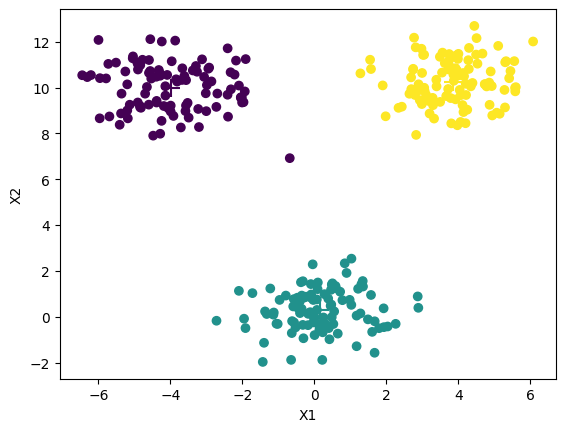

In [3]:
plt.scatter(data.X1, data.X2, c=kmeans.labels_)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="+", s=169, c=range(3))
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

In [4]:
from sklearn.metrics import silhouette_samples, silhouette_score
print(silhouette_score(data, kmeans.labels_))
print(mean(silhouette_samples(data, kmeans.labels_)[kmeans.labels_ == 0]))
print(mean(silhouette_samples(data, kmeans.labels_)[kmeans.labels_ == 1]))
print(mean(silhouette_samples(data, kmeans.labels_)[kmeans.labels_ == 2]))

0.7816266818416537
0.7433482229905469
0.8305466210576516
0.7718571854574335


In [5]:
init_X1 = [-2, 2, 0]
init_X2 = [0, 0, 10]
init_data = pd.DataFrame({"X1": init_X1, "X2": init_X2})
kmeans2 = KMeans(n_clusters=3, init=init_data).fit(data)
print(kmeans2.cluster_centers_)
print(kmeans2.labels_)
print(kmeans2.inertia_)
separation = 0
distance = lambda x1, x2: math.sqrt(((x1.X1 - x2.X1) ** 2) + ((x1.X2 - x2.X2) ** 2))
m = data.mean()
print(m)
for i in list(set(kmeans2.labels_)):
    mi = data.loc[kmeans2.labels_ == i, :].mean()
    Ci = len(data.loc[kmeans2.labels_ == i, :].index)
    separation += Ci * (distance(m, mi) ** 2)    
print(separation)
print(Ci)

[[-0.53359716  0.07729677]
 [ 1.08077979  0.62108533]
 [-0.09185615 10.12480759]]
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 1 0 0 1 0 1
 0 1 0 0 1 1 0 0 1 0 1 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 1 1 1 1 0 0 1
 0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 1 1 1 0 1
 1 1 0 1 0 0 1 1 0 1 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2]
3667.7696656329745
X1   -0.011618
X2    6.885259
dtype: float64
6466.304648456379
201


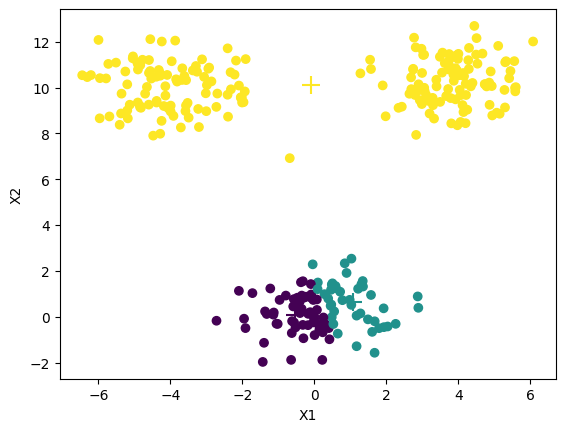

In [6]:
plt.scatter(data.X1, data.X2, c=kmeans2.labels_)
plt.scatter(kmeans2.cluster_centers_[:, 0], kmeans2.cluster_centers_[:, 1], marker="+", s=169, c=range(3))
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

In [7]:
print(silhouette_score(data, kmeans2.labels_))
print(mean(silhouette_samples(data, kmeans2.labels_)[kmeans2.labels_ == 0]))
print(mean(silhouette_samples(data, kmeans2.labels_)[kmeans2.labels_ == 1]))
print(mean(silhouette_samples(data, kmeans2.labels_)[kmeans2.labels_ == 2]))

0.45532884123093065
0.36744915222580526
0.27822638342080064
0.5172564307897247
